# Factorización QR y autovalores — prototipo del reto técnico

El reto pide dos APIs:
- **API en Go:** recibe una matriz rectangular (un array de arrays de números) y devuelve su **factorización QR**.
- **API en Node.js:** recibe las matrices Q y R y calcula **estadísticas**: máximo, mínimo, promedio, suma total y si alguna matriz es diagonal.

Antes de escribir las APIs, programamos todo en Python **a mano**, sin usar `np.linalg.qr`, y lo verificamos contra NumPy. Este notebook sirve de especificación: las funciones de Go y Node tendrán la misma lógica y los mismos nombres.

**Contenido**
1. Preparación
2. Validar la entrada
3. Validar el resultado: **Q ortogonal** y **R triangular superior**
4. Cuatro formas de calcular QR: Gram-Schmidt clásico, Gram-Schmidt modificado, Householder y Givens
5. Estabilidad: ¿qué método conviene?
6. Tiempos
7. Autovalores y autovectores con el algoritmo QR
8. Prototipo de la segunda API: estadísticas
9. Contrato JSON entre las APIs
10. Decisiones para las APIs

## 1. Preparación
`TOLERANCIA` es el margen para decidir si un número de punto flotante "es cero". Las operaciones con decimales dejan residuos como `1e-16`, así que nunca comparamos con `== 0`.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TOLERANCIA = 1e-10      # margen para considerar que un valor es cero
MAX_DIMENSION = 200     # tamaño máximo de filas y columnas que aceptará la API (Q y R de 200x200 ya son ~2 MB de JSON)
REPETICIONES = 5        # repeticiones para medir tiempos

np.set_printoptions(precision=4, suppress=True)

## 2. Validar la entrada
La API recibe un JSON, así que la matriz llega como una lista de listas. Antes de calcular revisamos que:
- no esté vacía;
- todas las filas tengan la misma cantidad de elementos (matriz **rectangular**);
- todos los elementos sean números finitos (no texto, ni booleanos, ni infinito);
- no supere el tamaño máximo. La QR cuesta $O(m \cdot n^2)$ operaciones, así que una matriz enorme bloquearía la API.

Si algo falla, la función lanza un error con un mensaje claro. La API lo devolverá como error 400.

In [2]:
def validar_matriz(datos):
    """Convierte un array de arrays en una matriz NumPy y revisa que sea una matriz rectangular válida."""
    if not isinstance(datos, list) or len(datos) == 0:
        raise ValueError("La matriz debe ser un arreglo no vacío de filas")
    columnas = None
    for i, fila in enumerate(datos):
        if not isinstance(fila, list) or len(fila) == 0:
            raise ValueError(f"La fila {i} debe ser un arreglo no vacío")
        if columnas is None:
            columnas = len(fila)
        elif len(fila) != columnas:
            raise ValueError(f"La fila {i} tiene {len(fila)} elementos y la fila 0 tiene {columnas}: la matriz no es rectangular")
        for j, valor in enumerate(fila):
            if isinstance(valor, bool) or not isinstance(valor, (int, float)) or not np.isfinite(valor):
                raise ValueError(f"El elemento [{i}][{j}] no es un número finito: {valor!r}")
    if len(datos) > MAX_DIMENSION or columnas > MAX_DIMENSION:
        raise ValueError(f"La matriz supera el tamaño máximo de {MAX_DIMENSION} x {MAX_DIMENSION}")
    return np.array(datos, dtype=float)

In [3]:
pruebas = {
    "correcta 2x3": [[1, 2, 3], [4, 5, 6]],
    "vacía": [],
    "filas de distinto largo": [[1, 2], [3]],
    "con texto": [[1, "a"], [2, 3]],
    "con infinito": [[1, float("inf")], [2, 3]],
    "con booleano": [[True, 2], [3, 4]],
    "demasiado grande": [[0.0] * 201],
}
for nombre, datos in pruebas.items():
    try:
        M = validar_matriz(datos)
        print(f"{nombre:25s} -> válida, forma {M.shape}")
    except ValueError as e:
        print(f"{nombre:25s} -> rechazada: {e}")

correcta 2x3              -> válida, forma (2, 3)
vacía                     -> rechazada: La matriz debe ser un arreglo no vacío de filas
filas de distinto largo   -> rechazada: La fila 1 tiene 1 elementos y la fila 0 tiene 2: la matriz no es rectangular
con texto                 -> rechazada: El elemento [0][1] no es un número finito: 'a'
con infinito              -> rechazada: El elemento [0][1] no es un número finito: inf
con booleano              -> rechazada: El elemento [0][0] no es un número finito: True
demasiado grande          -> rechazada: La matriz supera el tamaño máximo de 200 x 200


## 3. Validar el resultado: Q ortogonal y R triangular
Una factorización QR es correcta solo si cumple **tres reglas a la vez**:

| Regla | Qué significa | Cómo se mide |
|---|---|---|
| **Q ortogonal** | Las columnas de Q tienen largo 1 y son perpendiculares entre sí: $Q^T Q = I$ | mayor diferencia entre $Q^T Q$ y la identidad |
| **R triangular superior** | Todo lo que está debajo de la diagonal de R es 0 | mayor valor absoluto debajo de la diagonal |
| **Q·R = A** | Al multiplicar Q por R se recupera la matriz original | mayor diferencia entre $Q R$ y $A$, relativa al tamaño de A |

Cada regla se cumple si su error es menor o igual que `TOLERANCIA`.

Las funciones de error se programan con bucles, igual que se harán en Go, y luego se comparan con la versión de NumPy.

In [4]:
def error_ortogonalidad(Q):
    """Mayor diferencia entre QᵀQ y la identidad. Si las columnas de Q son ortonormales, es cercano a 0."""
    filas, columnas = Q.shape
    peor = 0.0
    for i in range(columnas):
        for j in range(columnas):
            producto = 0.0
            for k in range(filas):
                producto += Q[k][i] * Q[k][j]
            esperado = 1.0 if i == j else 0.0
            peor = max(peor, abs(producto - esperado))
    return peor


def error_triangular(R):
    """Mayor valor absoluto debajo de la diagonal. En una matriz triangular superior es 0."""
    peor = 0.0
    for i in range(R.shape[0]):
        for j in range(min(i, R.shape[1])):
            peor = max(peor, abs(R[i][j]))
    return peor


def error_reconstruccion(A, Q, R):
    """Mayor diferencia entre Q·R y A, relativa al mayor valor de A."""
    escala = max(1.0, np.abs(A).max())
    return np.abs(Q @ R - A).max() / escala


def validar_qr(A, Q, R, tol=TOLERANCIA):
    """Devuelve, por cada regla, si se cumple y el error medido."""
    errores = {
        "Q ortogonal": error_ortogonalidad(Q),
        "R triangular": error_triangular(R),
        "Q·R = A": error_reconstruccion(A, Q, R),
    }
    return {regla: {"cumple": bool(error <= tol), "error": float(error)} for regla, error in errores.items()}


def mostrar_validacion(validacion):
    for regla, r in validacion.items():
        print(f"  {'✅' if r['cumple'] else '❌'} {regla:13s} error = {r['error']:.1e}")

Comprobamos las funciones con la QR de NumPy, que sabemos que es correcta:

In [5]:
A = np.random.default_rng(0).normal(size=(5, 3))
Q, R = np.linalg.qr(A, mode="complete")

print("Error de ortogonalidad  a mano:", f"{error_ortogonalidad(Q):.1e}", "| NumPy:", f"{np.abs(Q.T @ Q - np.eye(5)).max():.1e}")
print("Error triangular        a mano:", f"{error_triangular(R):.1e}", "| NumPy:", f"{np.abs(np.tril(R, -1)).max():.1e}")
print("\nQR de NumPy:")
mostrar_validacion(validar_qr(A, Q, R))

Error de ortogonalidad  a mano: 4.4e-16 | NumPy: 4.4e-16
Error triangular        a mano: 0.0e+00 | NumPy: 0.0e+00

QR de NumPy:
  ✅ Q ortogonal   error = 4.4e-16
  ✅ R triangular  error = 0.0e+00
  ✅ Q·R = A       error = 1.9e-16


¿Por qué no basta con revisar que **Q·R = A**? Porque hay matrices que reconstruyen A sin ser una QR. Dos ejemplos:
- **Q escalada:** multiplicamos Q por 1.01 y dividimos R entre 1.01. El producto sigue dando A, pero Q ya no es ortogonal.
- **A = A·I:** tomamos Q = A y R = identidad. El producto da A y R es triangular, pero Q no es ortogonal.

In [6]:
print("Q escalada:")
mostrar_validacion(validar_qr(A, Q * 1.01, R / 1.01))

print("\nQ = A, R = identidad:")
mostrar_validacion(validar_qr(A, A, np.eye(3)))

Q escalada:
  ❌ Q ortogonal   error = 2.0e-02
  ✅ R triangular  error = 0.0e+00
  ✅ Q·R = A       error = 1.4e-16

Q = A, R = identidad:
  ❌ Q ortogonal   error = 7.7e+00
  ✅ R triangular  error = 0.0e+00
  ✅ Q·R = A       error = 0.0e+00


## 4. Cuatro formas de calcular QR

| Método | Idea | Resultado | Restricciones |
|---|---|---|---|
| **Gram-Schmidt clásico** | A cada columna se le restan sus proyecciones sobre las columnas de Q ya calculadas, usando la columna **original** | QR reducida: Q es m×n, R es n×n | necesita m ≥ n y columnas independientes |
| **Gram-Schmidt modificado** | Igual, pero las proyecciones se restan sobre la columna **ya corregida**, una por una | QR reducida | mismas restricciones |
| **Householder** | En cada paso, un **reflejo** (como un espejo) deja ceros debajo de la diagonal de una columna completa | QR completa: Q es m×m, R es m×n | ninguna |
| **Givens** | En cada paso, una **rotación** de dos filas deja un cero debajo de la diagonal | QR completa | ninguna |

### 4.1 Gram-Schmidt clásico

In [7]:
TOL_DEPENDENCIA = 1e-14   # si lo que queda de una columna es menor a esto (relativo), la columna es dependiente


def gram_schmidt_clasico(A):
    """QR reducida. Cada columna se ortogonaliza contra las columnas ORIGINALES de A."""
    m, n = A.shape
    if m < n:
        raise ValueError("Gram-Schmidt necesita al menos tantas filas como columnas")
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for j in range(n):
        v = A[:, j].copy()
        for i in range(j):
            R[i, j] = Q[:, i] @ A[:, j]          # proyección de la columna original
            v -= R[i, j] * Q[:, i]
        R[j, j] = np.linalg.norm(v)
        if R[j, j] <= TOL_DEPENDENCIA * max(1.0, np.linalg.norm(A[:, j])):
            raise ValueError(f"La columna {j} depende linealmente de las anteriores")
        Q[:, j] = v / R[j, j]
    return Q, R

### 4.2 Gram-Schmidt modificado
La única diferencia está en la línea de la proyección: se usa `v`, la columna que ya se fue corrigiendo, en vez de `A[:, j]`. En aritmética exacta los dos dan lo mismo; con decimales, el modificado acumula menos error.

In [8]:
def gram_schmidt_modificado(A):
    """QR reducida. Cada columna se ortogonaliza contra la versión YA CORREGIDA de sí misma."""
    m, n = A.shape
    if m < n:
        raise ValueError("Gram-Schmidt necesita al menos tantas filas como columnas")
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for j in range(n):
        v = A[:, j].copy()
        for i in range(j):
            R[i, j] = Q[:, i] @ v                # proyección de la columna ya corregida
            v -= R[i, j] * Q[:, i]
        R[j, j] = np.linalg.norm(v)
        if R[j, j] <= TOL_DEPENDENCIA * max(1.0, np.linalg.norm(A[:, j])):
            raise ValueError(f"La columna {j} depende linealmente de las anteriores")
        Q[:, j] = v / R[j, j]
    return Q, R

### 4.3 Householder
En el paso `k`, el vector `x` es la columna `k` desde la diagonal hacia abajo. El reflejo $H = I - 2vv^T$ lo convierte en $(\pm\|x\|, 0, \dots, 0)$. Aplicar todos los reflejos a A da R; acumularlos da Q.

El signo de `v[0]` se elige igual al de `x[0]` para no restar dos números parecidos, que es donde se pierde precisión.

In [9]:
def householder(A):
    """QR completa con reflejos de Householder. Funciona con cualquier forma y rango."""
    m, n = A.shape
    R = A.copy()
    Q = np.eye(m)
    for k in range(min(m - 1, n)):
        x = R[k:, k]
        norma = np.linalg.norm(x)
        if norma == 0:
            continue                             # la columna ya tiene ceros debajo de la diagonal
        v = x.copy()
        v[0] += np.copysign(norma, x[0])         # mismo signo que x[0]: evita la cancelación
        v /= np.linalg.norm(v)
        R[k:, :] -= 2.0 * np.outer(v, v @ R[k:, :])
        Q[:, k:] -= 2.0 * np.outer(Q[:, k:] @ v, v)
        R[k + 1:, k] = 0.0                       # en teoría ya son ceros; se fija para quitar el residuo de redondeo
    return Q, R

### 4.4 Givens (rotaciones)
Para dejar en cero el elemento `R[i][j]`, se rota el par de filas `(i-1, i)` un ángulo θ elegido para que el segundo valor quede en 0:

$$\begin{pmatrix} c & s \\ -s & c \end{pmatrix} \begin{pmatrix} a \\ b \end{pmatrix} = \begin{pmatrix} r \\ 0 \end{pmatrix}, \quad r = \sqrt{a^2 + b^2},\ c = \cos\theta = a/r,\ s = \sin\theta = b/r$$

Q es el producto de todas las rotaciones. Este método conecta las dos lecturas del enunciado, que habla de "rotación de la matriz" y de "factorización QR": **la QR se puede calcular rotando la matriz**.

In [10]:
def givens(A):
    """QR completa con rotaciones de Givens: cada rotación pone en cero un elemento debajo de la diagonal."""
    m, n = A.shape
    R = A.copy()
    Q = np.eye(m)
    for j in range(n):
        for i in range(m - 1, j, -1):            # de abajo hacia arriba, hasta la diagonal
            a, b = R[i - 1, j], R[i, j]
            if b == 0:
                continue
            r = np.hypot(a, b)                   # sqrt(a² + b²) sin desbordar
            c, s = a / r, b / r
            G = np.array([[c, s], [-s, c]])
            R[[i - 1, i], :] = G @ R[[i - 1, i], :]
            Q[:, [i - 1, i]] = Q[:, [i - 1, i]] @ G.T
            R[i, j] = 0.0                        # en teoría ya es cero; se fija para quitar el residuo
    return Q, R

### 4.5 Una sola entrada para los cuatro métodos
La QR es única salvo por los signos: se puede cambiar el signo de una columna de Q y de la fila correspondiente de R, y el producto no cambia. Para que todos los métodos devuelvan la **misma** respuesta, dejamos la diagonal de R siempre positiva.

`factorizar_qr` elige el método por su nombre. En Go esto será el **patrón Strategy**: una interfaz con cuatro implementaciones.

In [11]:
def normalizar_signos(Q, R):
    """Cambia signos para que la diagonal de R sea positiva. Q·R no cambia."""
    Q, R = Q.copy(), R.copy()
    for i in range(min(R.shape)):
        if R[i, i] < 0:
            R[i, :] *= -1
            Q[:, i] *= -1
    return Q, R


METODOS = {
    "gram-schmidt-clasico": gram_schmidt_clasico,
    "gram-schmidt-modificado": gram_schmidt_modificado,
    "householder": householder,
    "givens": givens,
}


def factorizar_qr(A, metodo="householder"):
    if metodo not in METODOS:
        raise ValueError(f"Método desconocido: {metodo}. Opciones: {', '.join(METODOS)}")
    Q, R = METODOS[metodo](A)
    return normalizar_signos(Q, R)

### 4.6 Verificación contra NumPy
Comparamos R de cada método con la de `np.linalg.qr` (con los signos normalizados). Gram-Schmidt se compara con la QR reducida y los otros dos con la completa.

In [12]:
A = np.random.default_rng(1).normal(size=(6, 4))
_, R_reducida = normalizar_signos(*np.linalg.qr(A, mode="reduced"))
_, R_completa = normalizar_signos(*np.linalg.qr(A, mode="complete"))

for metodo in METODOS:
    Q, R = factorizar_qr(A, metodo)
    referencia = R_reducida if R.shape == R_reducida.shape else R_completa
    print(f"{metodo:24s} Q {Q.shape}, R {R.shape} | diferencia con NumPy: {np.abs(R - referencia).max():.1e}")
    mostrar_validacion(validar_qr(A, Q, R))

gram-schmidt-clasico     Q (6, 4), R (4, 4) | diferencia con NumPy: 2.2e-16
  ✅ Q ortogonal   error = 2.2e-16
  ✅ R triangular  error = 0.0e+00
  ✅ Q·R = A       error = 8.5e-17
gram-schmidt-modificado  Q (6, 4), R (4, 4) | diferencia con NumPy: 2.8e-16
  ✅ Q ortogonal   error = 2.2e-16
  ✅ R triangular  error = 0.0e+00
  ✅ Q·R = A       error = 8.5e-17
householder              Q (6, 6), R (6, 4) | diferencia con NumPy: 1.3e-15
  ✅ Q ortogonal   error = 4.4e-16
  ✅ R triangular  error = 0.0e+00
  ✅ Q·R = A       error = 1.1e-15
givens                   Q (6, 6), R (6, 4) | diferencia con NumPy: 4.4e-16
  ✅ Q ortogonal   error = 2.2e-16
  ✅ R triangular  error = 0.0e+00
  ✅ Q·R = A       error = 2.6e-16


## 5. Estabilidad: ¿qué método conviene?
Con matrices "fáciles" los cuatro métodos funcionan. La diferencia aparece con matrices **mal condicionadas**: aquellas cuyas columnas son casi paralelas, donde un pequeño error de redondeo cambia mucho el resultado. El **número de condición** mide esa dificultad: cuanto más grande, más difícil.

Casos de prueba:
- **Aleatoria 50×30:** fácil.
- **Hilbert:** $H_{ij} = 1/(i+j+1)$, el ejemplo clásico de matriz mal condicionada.
- **Läuchli:** tres columnas que solo se diferencian en $10^{-8}$.
- **Rango deficiente:** la segunda columna es el doble de la primera.
- **Ancha 2×3:** más columnas que filas. El enunciado dice "matriz rectangular" sin más, así que este caso puede llegar.

In [13]:
def hilbert(n):
    return np.array([[1.0 / (i + j + 1) for j in range(n)] for i in range(n)])


EPS_LAUCHLI = 1e-8
CASOS = {
    "Aleatoria 50x30": np.random.default_rng(0).normal(size=(50, 30)),
    "Hilbert 6x6": hilbert(6),
    "Hilbert 10x10": hilbert(10),
    "Läuchli": np.array([[1, 1, 1], [EPS_LAUCHLI, 0, 0], [0, EPS_LAUCHLI, 0], [0, 0, EPS_LAUCHLI]]),
    "Rango deficiente": np.array([[1.0, 2], [2, 4], [3, 6]]),
    "Ancha 2x3": np.array([[1.0, 2, 3], [4, 5, 6]]),
}

filas = []
for caso, A in CASOS.items():
    fila = {"caso": caso, "condición": f"{np.linalg.cond(A):.0e}"}
    for metodo in METODOS:
        try:
            Q, R = factorizar_qr(A, metodo)
            v = validar_qr(A, Q, R)
            reglas = all(r["cumple"] for r in v.values())
            fila[metodo] = f"{'✅' if reglas else '❌'} {v['Q ortogonal']['error']:.0e}"
        except ValueError as e:
            fila[metodo] = "⛔ columnas dependientes" if "depende" in str(e) else "⛔ más columnas que filas"
    filas.append(fila)

pd.set_option("display.width", 200)
estabilidad = pd.DataFrame(filas).set_index("caso")
print("Valor mostrado: error de ortogonalidad de Q. ✅ cumple las tres reglas, ❌ no cumple alguna, ⛔ el método rechaza la matriz.")
estabilidad

Valor mostrado: error de ortogonalidad de Q. ✅ cumple las tres reglas, ❌ no cumple alguna, ⛔ el método rechaza la matriz.


,condición,gram-schmidt-clasico,gram-schmidt-modificado,householder,givens
caso,,,,,
Aleatoria 50x30,9e+00,✅ 4e-16,✅ 4e-16,✅ 1e-15,✅ 2e-15
Hilbert 6x6,1e+07,❌ 2e-04,✅ 9e-11,✅ 7e-16,✅ 1e-15
Hilbert 10x10,2e+13,❌ 1e+00,❌ 5e-05,✅ 9e-16,✅ 7e-16
Läuchli,2e+08,❌ 5e-01,❌ 7e-09,✅ 1e-15,✅ 2e-16
Rango deficiente,2e+16,⛔ columnas dependientes,⛔ columnas dependientes,✅ 8e-16,✅ 1e-16
Ancha 2x3,1e+01,⛔ más columnas que filas,⛔ más columnas que filas,✅ 4e-16,✅ 0e+00


El gráfico repite la prueba con matrices de Hilbert de tamaño 2 a 12, que son cada vez más difíciles. El eje Y es el error de ortogonalidad de Q en escala logarítmica; la línea punteada es `TOLERANCIA`.

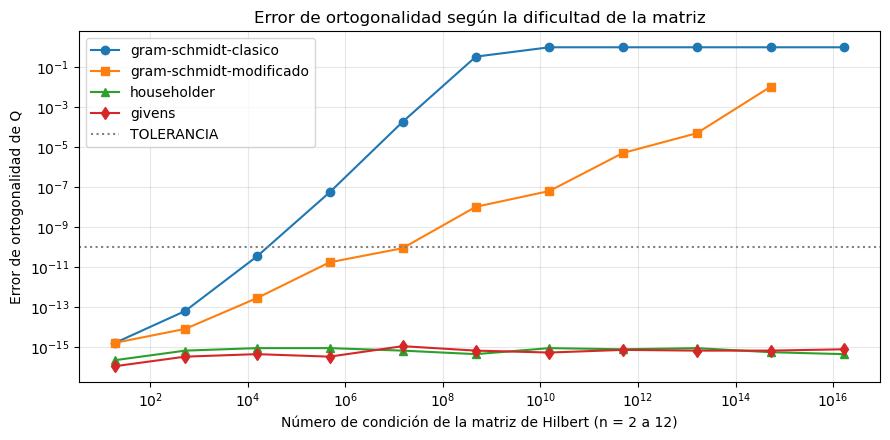

In [14]:
tamanos_hilbert = range(2, 13)
curvas = {metodo: [] for metodo in METODOS}
condiciones = []
for n in tamanos_hilbert:
    H = hilbert(n)
    condiciones.append(np.linalg.cond(H))
    for metodo in METODOS:
        try:
            Q, _ = factorizar_qr(H, metodo)
            curvas[metodo].append(np.abs(Q.T @ Q - np.eye(Q.shape[1])).max())
        except ValueError:
            curvas[metodo].append(np.nan)    # el método rechazó la matriz por columnas dependientes

plt.figure(figsize=(9, 4.5))
for (metodo, errores), marca in zip(curvas.items(), ["o-", "s-", "^-", "d-"]):
    plt.semilogy(condiciones, errores, marca, label=metodo)
plt.axhline(TOLERANCIA, color="gray", linestyle=":", label="TOLERANCIA")
plt.xscale("log")
plt.xlabel("Número de condición de la matriz de Hilbert (n = 2 a 12)")
plt.ylabel("Error de ortogonalidad de Q")
plt.title("Error de ortogonalidad según la dificultad de la matriz")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Qué vimos:**

- Con la matriz aleatoria, los cuatro métodos cumplen las tres reglas con errores cercanos a $10^{-15}$.
- **Gram-Schmidt clásico** falla desde Hilbert 6×6: el error de Q es $2 \times 10^{-4}$. Con Hilbert 10×10 el error llega a 1, es decir, Q no es ortogonal en absoluto. Aun así, Q·R sigue dando A: **solo la regla "Q ortogonal" detecta el problema**.
- **Gram-Schmidt modificado** aguanta Hilbert 6×6, justo por debajo de la tolerancia, pero falla con Hilbert 10×10 y con Läuchli.
- **Householder y Givens** se mantienen cerca de $10^{-15}$ en todos los casos, incluidas la matriz de rango deficiente y la matriz ancha, que Gram-Schmidt ni siquiera acepta.
- En el gráfico, el error de los dos Gram-Schmidt crece con el número de condición, y el del clásico crece mucho más rápido. El de Householder y Givens no depende de la condición.

**Conclusión:** Gram-Schmidt es el método más fácil de explicar, pero no sirve como método por defecto en una API que acepta cualquier matriz rectangular. Householder y Givens sí.

## 6. Tiempos
Medimos matrices cuadradas aleatorias de distintos tamaños, con el promedio y la desviación de 5 repeticiones. Se incluye `np.linalg.qr` como referencia: usa LAPACK, que está escrito en Fortran y C.

Los tiempos en Python sirven para **comparar los métodos entre sí**. En Go todo será código compilado, así que los tiempos absolutos serán menores.

In [15]:
def medir(funcion, *args, repeticiones=REPETICIONES):
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        funcion(*args)
        tiempos.append((time.perf_counter() - inicio) * 1000)
    return np.mean(tiempos), np.std(tiempos)


TAMANOS = [25, 50, 100, 200]
filas = []
for n in TAMANOS:
    A = np.random.default_rng(n).normal(size=(n, n))
    fila = {"tamaño": f"{n}x{n}"}
    for metodo in METODOS:
        media, desviacion = medir(factorizar_qr, A, metodo)
        fila[metodo + " (ms)"] = media
        fila[metodo + " ±"] = desviacion
    fila["NumPy (ms)"], fila["NumPy ±"] = medir(np.linalg.qr, A)
    filas.append(fila)

tiempos = pd.DataFrame(filas).set_index("tamaño")
tiempos[[c for c in tiempos.columns if c.endswith("(ms)")]].round(2)

,gram-schmidt-clasico (ms),gram-schmidt-modificado (ms),householder (ms),givens (ms),NumPy (ms)
tamaño,,,,,
25x25,0.94,0.85,0.51,3.93,0.20
50x50,4.21,3.20,1.18,14.27,1.30
100x100,18.27,15.90,3.36,66.49,1.54
200x200,66.18,57.48,19.48,276.53,1.45


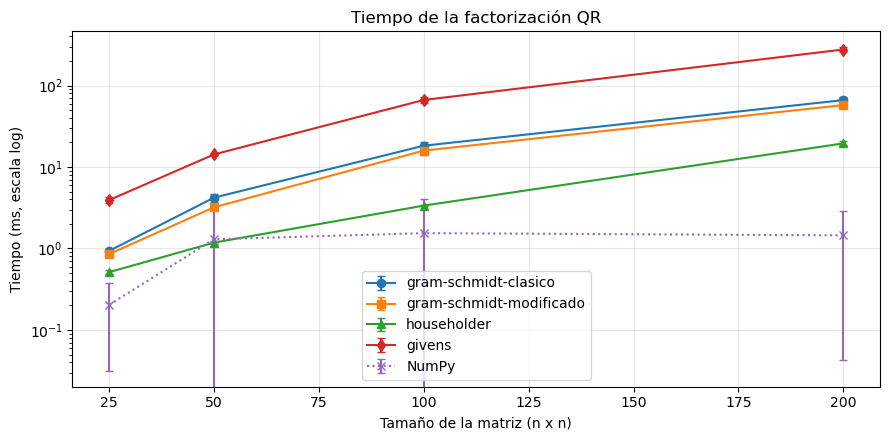

In [16]:
plt.figure(figsize=(9, 4.5))
for columna, marca in zip([c for c in tiempos.columns if c.endswith("(ms)")], ["o-", "s-", "^-", "d-", "x:"]):
    plt.errorbar(TAMANOS, tiempos[columna], yerr=tiempos[columna.replace("(ms)", "±")], fmt=marca,
                 capsize=3, label=columna.replace(" (ms)", ""))
plt.yscale("log")
plt.xlabel("Tamaño de la matriz (n x n)")
plt.ylabel("Tiempo (ms, escala log)")
plt.title("Tiempo de la factorización QR")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Qué vimos:**

- **Householder es el más rápido de los cuatro** en todos los tamaños. Con 200×200 tarda unos 20 ms, frente a 55-70 ms de Gram-Schmidt y unos 300 ms de Givens.
- **Givens es el más lento** con matrices llenas. Hace una rotación por cada elemento debajo de la diagonal (unas $n^2/2$ rotaciones), y cada una actualiza dos filas completas. Conviene cuando la matriz ya tiene muchos ceros, porque solo rota donde hay un valor distinto de cero.
- NumPy (LAPACK) tarda menos de 2 ms: es la referencia de código compilado y optimizado.

**Conclusión:** Householder es a la vez el más estable y el más rápido de nuestras implementaciones.

## 7. Autovalores y autovectores con el algoritmo QR
Un **autovector** $v$ de una matriz cuadrada A es un vector que, al multiplicarlo por A, solo cambia de tamaño: $Av = \lambda v$. El número $\lambda$ es su **autovalor**.

El **algoritmo QR** los calcula repitiendo dos pasos:

$$A_0 = A, \qquad A_k = Q_k R_k, \qquad A_{k+1} = R_k Q_k$$

- $A_{k+1} = Q_k^T A_k Q_k$, así que todas las $A_k$ tienen los mismos autovalores que A.
- En una matriz **simétrica**, $A_k$ se va volviendo diagonal, y los autovalores quedan en la diagonal.
- El producto de todas las $Q_k$ da los **autovectores**, que salen ortogonales entre sí.

**Límites de esta versión:**
- Solo matrices **simétricas**. Una matriz no simétrica puede tener autovalores complejos, y entonces $A_k$ nunca se vuelve diagonal.
- Si dos autovalores tienen el mismo valor absoluto y distinto signo ($\lambda$ y $-\lambda$), esta versión sin desplazamientos no converge. Las librerías usan *desplazamientos de Wilkinson* para evitarlo; aquí se detiene con un error al llegar al máximo de iteraciones.

In [17]:
MAX_ITERACIONES = 10_000


def autovalores_qr(A, tol=TOLERANCIA, max_iteraciones=MAX_ITERACIONES):
    """Autovalores y autovectores de una matriz simétrica con el algoritmo QR (usa householder)."""
    n, m = A.shape
    if n != m:
        raise ValueError("Los autovalores solo existen para matrices cuadradas")
    escala = max(1.0, np.abs(A).max())
    if np.abs(A - A.T).max() > tol * escala:
        raise ValueError("Solo se aceptan matrices simétricas: las demás pueden tener autovalores complejos")
    Ak = A.copy()
    V = np.eye(n)
    for iteracion in range(1, max_iteraciones + 1):
        Q, R = householder(Ak)
        Ak = R @ Q
        V = V @ Q
        if np.abs(np.tril(Ak, -1)).max() <= tol * escala:
            return np.diag(Ak), V, iteracion
    raise ValueError(f"No convergió en {max_iteraciones} iteraciones")

**Ejemplo de ML: matriz de covarianza.** En PCA, los autovectores de la matriz de covarianza son las direcciones en las que los datos varían más, y sus autovalores indican cuánto varían en cada una. La matriz de covarianza siempre es simétrica.

Generamos 200 puntos con 4 variables relacionadas entre sí y comparamos con `np.linalg.eigh`. También validamos que se cumpla $Av = \lambda v$ y que los autovectores sean ortogonales.

In [18]:
rng = np.random.default_rng(7)
base = rng.normal(size=(200, 2))
datos = np.column_stack([base[:, 0], 0.8 * base[:, 0] + 0.3 * base[:, 1] + rng.normal(scale=0.2, size=200), base[:, 1], rng.normal(scale=0.5, size=200)])
C = np.cov(datos, rowvar=False)

autovalores, autovectores, iteraciones = autovalores_qr(C)
orden = np.argsort(autovalores)[::-1]
autovalores, autovectores = autovalores[orden], autovectores[:, orden]

referencia = np.sort(np.linalg.eigvalsh(C))[::-1]
print("Matriz de covarianza:\n", C)
print(f"\nIteraciones: {iteraciones}")
print("Autovalores (algoritmo QR):", autovalores)
print("Autovalores (NumPy eigh):  ", referencia)
print(f"Mayor diferencia: {np.abs(autovalores - referencia).max():.1e}")
print(f"\nError de A·v = λ·v:            {np.abs(C @ autovectores - autovectores * autovalores).max():.1e}")
print(f"Error de ortogonalidad de V:   {error_ortogonalidad(autovectores):.1e}")
print(f"Varianza explicada por el 1.er autovector: {autovalores[0] / autovalores.sum():.1%}")

Matriz de covarianza:
 [[ 0.8499  0.7123  0.0991 -0.0388]
 [ 0.7123  0.6996  0.3255 -0.033 ]
 [ 0.0991  0.3255  0.8622  0.0077]
 [-0.0388 -0.033   0.0077  0.2544]]

Iteraciones: 32
Autovalores (algoritmo QR): [1.6095 0.7857 0.2517 0.0192]
Autovalores (NumPy eigh):   [1.6095 0.7857 0.2517 0.0192]
Mayor diferencia: 1.6e-15

Error de A·v = λ·v:            5.1e-11
Error de ortogonalidad de V:   1.8e-15
Varianza explicada por el 1.er autovector: 60.4%


**La matriz de rotación no tiene autovalores reales.** Rotar 90° en el plano es la matriz $\begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$. Ningún vector del plano queda en su misma dirección al rotarlo 90°, así que no hay autovalores reales: son $\pm i$. La función la rechaza porque no es simétrica.

In [19]:
rotacion_90 = np.array([[0.0, -1.0], [1.0, 0.0]])
try:
    autovalores_qr(rotacion_90)
except ValueError as e:
    print("Algoritmo QR:", e)
print("NumPy eigvals:", np.linalg.eigvals(rotacion_90))

Algoritmo QR: Solo se aceptan matrices simétricas: las demás pueden tener autovalores complejos
NumPy eigvals: [0.+1.j 0.-1.j]


## 8. Prototipo de la segunda API: estadísticas
La API de Node recibe Q y R y calcula, **recorriendo los valores una sola vez**:
- valor máximo y mínimo de todas las matrices;
- suma total y promedio;
- si cada matriz es diagonal, y si **alguna** lo es.

Decisiones:
- **Diagonal** significa que todo lo que está fuera de la diagonal principal es cero (con `TOLERANCIA`). La definición se aplica también a matrices no cuadradas.
- La suma usa el **método de Neumaier**: guarda en `compensacion` lo que se pierde por redondeo en cada suma y lo agrega al final.

Dato útil: **R es diagonal exactamente cuando las columnas de A son perpendiculares entre sí.**

In [20]:
def estadisticas(matrices, tol=TOLERANCIA):
    """Estadísticas de todas las matrices en una sola pasada. `matrices` es un diccionario nombre -> matriz."""
    maximo, minimo = -np.inf, np.inf
    suma, compensacion, cantidad = 0.0, 0.0, 0
    diagonales = {}
    for nombre, M in matrices.items():
        es_diagonal = True
        for i, fila in enumerate(M):
            for j, valor in enumerate(fila):
                maximo = max(maximo, valor)
                minimo = min(minimo, valor)
                t = suma + valor                       # suma de Neumaier
                if abs(suma) >= abs(valor):
                    compensacion += (suma - t) + valor
                else:
                    compensacion += (valor - t) + suma
                suma = t
                cantidad += 1
                if i != j and abs(valor) > tol:
                    es_diagonal = False
        diagonales[nombre] = es_diagonal
    suma += compensacion
    return {
        "maximo": float(maximo),
        "minimo": float(minimo),
        "suma": float(suma),
        "promedio": float(suma / cantidad),
        "cantidad_valores": cantidad,
        "es_diagonal": diagonales,
        "alguna_diagonal": any(diagonales.values()),
    }

In [21]:
ejemplos = {
    "columnas perpendiculares": np.array([[1.0, 1], [1, -1], [0, 0]]),
    "columnas no perpendiculares": np.array([[1.0, 2], [3, 4], [5, 6]]),
}
for nombre, A in ejemplos.items():
    Q, R = factorizar_qr(A)
    resultado = estadisticas({"Q": Q, "R": R})
    todos = np.concatenate([Q.ravel(), R.ravel()])
    print(f"--- {nombre}\nR =\n{R}")
    print(json.dumps(resultado, indent=2, ensure_ascii=False))
    print(f"Verificación con NumPy -> máx {todos.max():.4f}, mín {todos.min():.4f}, suma {todos.sum():.4f}, promedio {todos.mean():.4f}\n")

--- columnas perpendiculares
R =
[[ 1.4142 -0.    ]
 [ 0.      1.4142]
 [ 0.      0.    ]]
{
  "maximo": 1.414213562373095,
  "minimo": -0.7071067811865475,
  "suma": 5.242640687119284,
  "promedio": 0.3495093791412856,
  "cantidad_valores": 15,
  "es_diagonal": {
    "Q": false,
    "R": true
  },
  "alguna_diagonal": true
}
Verificación con NumPy -> máx 1.4142, mín -0.7071, suma 5.2426, promedio 0.3495

--- columnas no perpendiculares
R =
[[5.9161 7.4374]
 [0.     0.8281]
 [0.     0.    ]]
{
  "maximo": 7.437357441610946,
  "minimo": -0.816496580927726,
  "suma": 16.53087222564354,
  "promedio": 1.1020581483762362,
  "cantidad_valores": 15,
  "es_diagonal": {
    "Q": false,
    "R": false
  },
  "alguna_diagonal": false
}
Verificación con NumPy -> máx 7.4374, mín -0.8165, suma 16.5309, promedio 1.1021



**Por qué la tolerancia es necesaria:** sin ella, una matriz que en teoría es diagonal puede no salir diagonal por residuos de `1e-17`.

In [22]:
casi_diagonal = np.array([[2.0, 1e-17], [0.0, 3.0]])
print("Con TOLERANCIA:", estadisticas({"M": casi_diagonal})["alguna_diagonal"])
print("Con tolerancia 0:", estadisticas({"M": casi_diagonal}, tol=0.0)["alguna_diagonal"])

Con TOLERANCIA: True
Con tolerancia 0: False


## 9. Contrato JSON entre las APIs
Así se verían las peticiones y respuestas. La API de Go valida su propio resultado con las tres reglas y las incluye en la respuesta, para que el cliente vea que Q es ortogonal y R triangular.

In [23]:
def api_go_qr(cuerpo):
    """Simula POST /qr de la API en Go."""
    A = validar_matriz(cuerpo["matriz"])
    metodo = cuerpo.get("metodo", "householder")
    Q, R = factorizar_qr(A, metodo)
    return {
        "metodo": metodo,
        "dimensiones": {"filas": A.shape[0], "columnas": A.shape[1]},
        "q": Q.round(12).tolist(),
        "r": R.round(12).tolist(),
        "validaciones": validar_qr(A, Q, R),
    }


def api_node_estadisticas(cuerpo):
    """Simula POST /estadisticas de la API en Node."""
    return estadisticas({"q": cuerpo["q"], "r": cuerpo["r"]})


peticion = {"matriz": [[1, 2], [3, 4], [5, 6]], "metodo": "householder"}
respuesta_go = api_go_qr(peticion)
respuesta_node = api_node_estadisticas({"q": respuesta_go["q"], "r": respuesta_go["r"]})

print("POST /qr  (API en Go)\nPetición:", json.dumps(peticion))
print("Respuesta:", json.dumps(respuesta_go, indent=2, ensure_ascii=False))
print("\nPOST /estadisticas  (API en Node)\nRespuesta:", json.dumps(respuesta_node, indent=2, ensure_ascii=False))

POST /qr  (API en Go)
Petición: {"matriz": [[1, 2], [3, 4], [5, 6]], "metodo": "householder"}
Respuesta: {
  "metodo": "householder",
  "dimensiones": {
    "filas": 3,
    "columnas": 2
  },
  "q": [
    [
      0.169030850946,
      0.897085227145,
      0.408248290464
    ],
    [
      0.507092552837,
      0.276026223737,
      -0.816496580928
    ],
    [
      0.845154254729,
      -0.345032779671,
      0.408248290464
    ]
  ],
  "r": [
    [
      5.9160797831,
      7.437357441611
    ],
    [
      0.0,
      0.828078671211
    ],
    [
      0.0,
      0.0
    ]
  ],
  "validaciones": {
    "Q ortogonal": {
      "cumple": true,
      "error": 2.220446049250313e-16
    },
    "R triangular": {
      "cumple": true,
      "error": 0.0
    },
    "Q·R = A": {
      "cumple": true,
      "error": 1.4802973661668753e-16
    }
  }
}

POST /estadisticas  (API en Node)
Respuesta: {
  "maximo": 7.437357441611,
  "minimo": -0.816496580928,
  "suma": 16.530872225645,
  "promedio": 1

## 10. Decisiones para las APIs

| Tema | Decisión | Por qué |
|---|---|---|
| Método por defecto | **Householder** | Cumple las tres reglas en todos los casos y es el más rápido de los cuatro (secciones 5 y 6) |
| Otros métodos | `gram-schmidt-clasico`, `gram-schmidt-modificado` y `givens`, elegidos con el campo `metodo` | Patrón Strategy en Go. Gram-Schmidt muestra lo visto en clase; Givens calcula la QR **con rotaciones**, lo que concilia las dos lecturas del enunciado |
| Forma de la QR | Completa (Q m×m, R m×n) con Householder y Givens; reducida (Q m×n, R n×n) con Gram-Schmidt | Gram-Schmidt solo produce la reducida |
| Signos | Diagonal de R siempre positiva | Con esto todos los métodos dan la misma respuesta y las pruebas son deterministas |
| Validación de la entrada | Matriz no vacía, rectangular, números finitos, máximo 200×200 (Q y R de 200×200 ya suman unos 2 MB de JSON; Lambda responde hasta 6 MB) | Si falla, error **400** con el mensaje de `validar_matriz` |
| Matrices que Gram-Schmidt no acepta | Más columnas que filas, o columnas dependientes | Error **400** que sugiere usar `householder` |
| Validación del resultado | **Q ortogonal**, **R triangular superior** y **Q·R = A**, con `TOLERANCIA` = $10^{-10}$; se incluyen en la respuesta | Si alguna regla no se cumple (por ejemplo, Gram-Schmidt con Hilbert 10×10), la API en Go responde **422** y **no** llama a la API de Node |
| Estadísticas (API Node) | Una sola pasada, suma de Neumaier, "diagonal" con `TOLERANCIA`, resultado por matriz y global | Sección 8 |
| Autovalores | Endpoint extra opcional `POST /autovalores`, solo matrices simétricas | Muestra el uso de la QR más allá del enunciado (sección 7), sin retrasar lo obligatorio |